# KNN Classification Model (Breast Cancer Dataset)
This notebook covers:
- Loading data
- Preprocessing
- Training KNN
- Evaluating Accuracy
- Distance Metric usage
- Cross Validation to find best K

## Loading Libraries

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [7]:
# Load dataset
df = pd.read_csv("D:/Machine_learning_innomatics/knn/breast cancer.xls")
df.sample(5)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
339,89812,M,23.51,24.27,155.10,1747.0,0.10690,0.12830,0.23080,0.14100,...,30.73,202.40,2906.0,0.1515,0.2678,0.4819,0.20890,0.2593,0.07738,NaN
379,9013838,M,11.08,18.83,73.30,361.6,0.12160,0.21540,0.16890,0.06367,...,32.82,91.76,508.1,0.2184,0.9379,0.8402,0.25240,0.4154,0.14030,NaN
371,9012568,B,15.19,13.21,97.65,711.8,0.07963,0.06934,0.03393,0.02657,...,15.73,104.50,819.1,0.1126,0.1737,0.1362,0.08178,0.2487,0.06766,NaN
199,877500,M,14.45,20.22,94.49,642.7,0.09872,0.12060,0.11800,0.05980,...,30.12,117.90,1044.0,0.1552,0.4056,0.4967,0.18380,0.4753,0.10130,NaN
17,84862001,M,16.13,20.68,108.10,798.8,0.11700,0.20220,0.17220,0.10280,...,31.48,136.80,1315.0,0.1789,0.4233,0.4784,0.20730,0.3706,0.11420,NaN


## Understand the data

In [8]:
print ('Shape        ------>', df.shape)
print ('Each Column and data type and its count','\n')
print ( df.info())

Shape        ------> (569, 33)
Each Column and data type and its count 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture

## Data Cleaning 

In [9]:
#DROP ALERT 1 : Unnamed:32 column has all nulls. Safe to remove the column.
df = df.drop(['Unnamed: 32'],axis=1)

In [10]:
df.isnull().sum()

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [11]:
df.diagnosis.value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

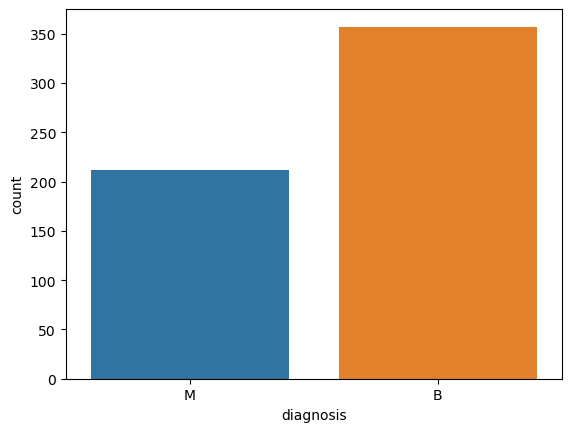

In [12]:
#Plot each class freequency
sns.countplot(x='diagnosis',data=df)
plt.show()

In [13]:
# Drop unnecessary columns if present
if 'id' in df.columns:
    df.drop('id', axis=1, inplace=True)


#Replace Label column (diagnosis) into binary codes
df['diagnosis'] = df['diagnosis'].replace({'M':0,'B':1})

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

## Train-Test Split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Scaling the Numerical Data

In [15]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Model Training and Prediction 

In [30]:
# Using Euclidean Distance (default: metric='minkowski', p=2)
knn = KNeighborsClassifier(n_neighbors=9, metric='minkowski', p=2)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred))

y_prob = knn.predict_proba(X_test)[:,1]  # needed for ROC & Log Loss

Accuracy: 0.9649122807017544


## Cross-Validation for find the best K

In [17]:
k_values = range(1, 21)
scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X, y, cv=5, scoring='accuracy')
    scores.append(score.mean())




best_k = k_values[scores.index(max(scores))]
print("Best K:", best_k)

Best K: 1


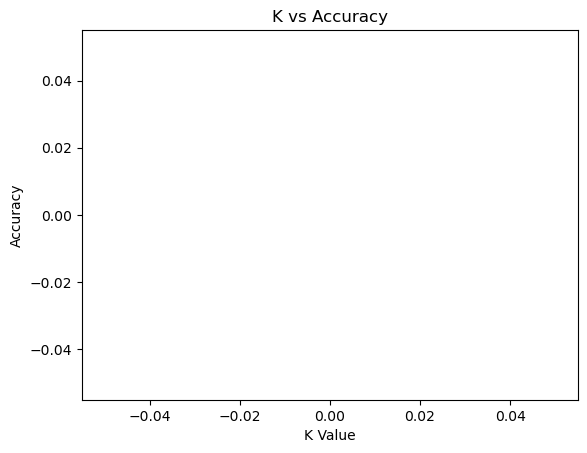

In [32]:
plt.plot(k_values, scores, marker='o')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('K vs Accuracy')
plt.show()

# 📊 Classification Evaluation Metrics (Breast Cancer Detection)

After training our KNN model, we now evaluate how well it performs.

In this problem:
- 1 → Malignant (Cancer)
- 0 → Benign (No Cancer)

We will study:
- Accuracy
- Confusion Matrix
- Precision & Recall
- F1 Score
- ROC AUC
- Log Loss

In [19]:
# Importing the metrices

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    log_loss,
    RocCurveDisplay,
    recall_score,
    precision_score,
    f1_score
)

##  1. Accuracy

### Formula:
Accuracy = (Correct Predictions) / (Total Predictions)

### Meaning:
Out of all patients, how many were correctly classified?

### In medical context:
- High accuracy means overall model is correct
- BUT it can be misleading if classes are imbalanced

⚠️ Example:
If 95% patients are healthy, predicting all as healthy gives 95% accuracy → but useless model!

### Use when:

    Dataset is balanced
    
    All errors are equally important

### Limitations:

    Misleading with imbalanced data    

In [20]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

precision1 = precision_score(y_test,y_pred)

Accuracy: 0.9649122807017544


##  2. Confusion Matrix

This is the most important table.

|                | Predicted Malignant | Predicted Benign |
|----------------|--------------------|------------------|
| Actual Malignant | TP | FN |
| Actual Benign    | FP | TN |

### Meaning:
- TP → Cancer correctly detected
- TN → Healthy correctly detected
- FP → Healthy but predicted cancer (False Alarm)
- FN → Cancer but missed (Dangerous)

⚠️ In healthcare:
FN is the most dangerous (missing cancer)

### Use when:

    You want complete understanding of errors

### Limitations:

    Not a single number → harder to summarize

    Not ideal for quick comparison    

In [21]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[41  2]
 [ 2 69]]


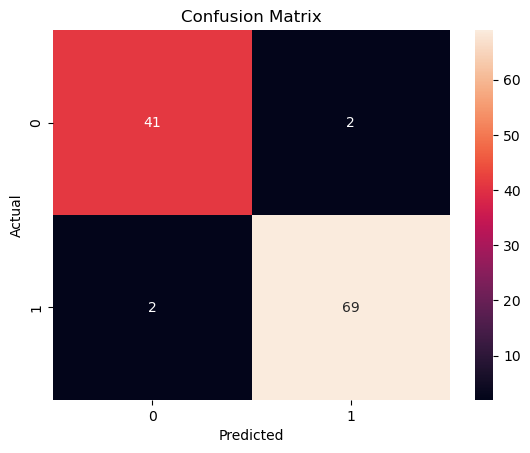

In [22]:
# Visualization

import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

##  3. Precision & Recall

### 🔹 Precision
Precision = TP / (TP + FP)

 When model says "Cancer", how often is it correct?

✔ Important when false alarms are costly

---

### 🔹 Recall (Sensitivity)
Recall = TP / (TP + FN)

 Out of all actual cancer cases, how many did we detect?

✔ VERY important in medical diagnosis

---

### In Breast Cancer:
- Precision → Avoid unnecessary panic
- Recall → Avoid missing cancer (MOST IMPORTANT)

In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95        43
           1       0.97      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



##  4. F1 Score

F1 = Harmonic mean of Precision & Recall

 It balances both:
- False alarms (Precision)
- Missed cases (Recall)

### When to use:
- When both precision and recall matter
- When dataset is imbalanced

### In cancer detection:
F1 is very useful overall score

##  5. ROC Curve & AUC

### ROC Curve shows:
- True Positive Rate (Recall)
vs
- False Positive Rate

### Limitations:

    Can look good on imbalanced data

---

### AUC (Area Under Curve)

| Value | Meaning |
|------|--------|
| 1.0 | Perfect model |
| 0.9+ | Excellent |
| 0.5 | Random |

---

### In our case:
Higher AUC = Better cancer detection ability

ROC AUC Score: 0.9806747461513264


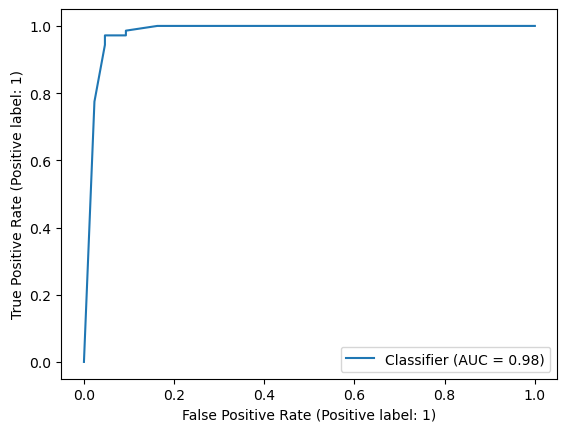

In [24]:
roc_score = roc_auc_score(y_test, y_prob)
print("ROC AUC Score:", roc_score)

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.show()

## Axes:
      X-axis → False Positive Rate (FPR)
             → “Out of all actual 0s, how many did we wrongly predict as 1?”


      Y-axis → True Positive Rate (TPR / Recall)
             → “Out of all actual 1s, how many did we correctly predict?”

##  6. Log Loss

Measures how confident the model is.

### Key idea:
- Correct + confident → Good
- Wrong + confident → Very bad

---

### Example:

| Actual | Prediction | Result |
|--------|-----------|--------|
| 1 | 0.9 | Good |
| 1 | 0.1 | Bad |

---

### Interpretation:
Lower Log Loss = Better model

### Limitations :

    Harder to interpret

    Sensitive to outliers (very confident wrong predictions)

---

### In healthcare:
We want model to be confidently correct

In [25]:
logloss = log_loss(y_test, y_prob)
print("Log Loss:", logloss)

Log Loss: 0.4011603508907251


#  Final Summary

| Metric | What it tells |
|--------|--------------|
| Accuracy | Overall correctness |
| Confusion Matrix | Detailed prediction breakdown |
| Precision | Correctness of positive predictions |
| Recall | Ability to detect actual positives |
| F1 Score | Balance of precision & recall |
| ROC AUC | Class separation ability |
| Log Loss | Confidence of predictions |

---

##  In Breast Cancer Detection:

 Most Important:
- Recall (Don't miss cancer)
- F1 Score (Balance)
- ROC AUC (Overall performance)

 Less reliable alone:
- Accuracy (can mislead)